# FeatureBot: Feature Engineering with AI Guidance
**Industrial Capstone Project - AI-Guided Feature Engineering for Adult Income Classification** (Project Code FB-FE-2025-Q3)

End-to-end Google Colab notebook: data load, EDA, baseline, two FeatureBot cycles (prompts + implementation), ablations, fairness diagnostics and mitigation, final model and holdout report.

### Instructions (clear steps)
1. Open this notebook in Google Colab (Runtime: Python 3, free tier is enough).
2. Upload **`adult.csv`** to the Colab working directory (left sidebar > Files > Upload), or change `DATA_PATH` in section 1.
3. Run all cells in order (**Runtime > Run all**). Total run time is about 4 to 6 minutes. Seeds are fixed (`SEED = 42`), splits are stratified 60/20/20, and every imputer / encoder / scaler is fitted on train only, so results are reproducible.
4. All outputs are written to `featurebot_outputs/`: `feature_registry.csv`, `experiments_log.csv`, EDA / baseline / fairness tables, figures and `prompts_and_responses.md`. The last cell zips the folder for download.

The ChatGPT / AI-assistant step happens outside the code: the filled prompts (Template A, B, C) are printed in section 4 and 6, followed by the recorded responses.

## 1. Setup & data load
Load `adult.csv`; normalise column names and target labels; handle `?` as missing; validate type and range rules; stratified 60/20/20 split.

In [1]:
%pip install -q category_encoders

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, time, json, warnings, subprocess
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib
try:
    get_ipython()  # noqa  (inside Colab / Jupyter keep the inline backend)
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

try:
    import category_encoders as ce
except ImportError:  # Colab usually needs this once
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "category_encoders"])
    import category_encoders as ce

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_recall_fscore_support, precision_recall_curve,
                             roc_curve, confusion_matrix, classification_report)

SEED = 42
N_FOLDS = 5
DATA_PATH = next((p for p in ["adult.csv", "/content/adult.csv"] if os.path.exists(p)), "adult.csv")
OUT_DIR = "featurebot_outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
NUMERIC_RAW = ["age", "fnlwgt", "educational_num", "capital_gain", "capital_loss", "hours_per_week"]
SENSITIVE = ["gender", "race", "marital_status"]      # the PDF's "sex" is the `gender` column in adult.csv
MIN_GROUP_N = 50                                       # subgroups smaller than this are flagged in parity ratios

# Decision rule used when pruning features (CV on the TRAIN split only)
KEEP_MIN_DAUC, KEEP_MIN_DF1, KEEP_MIN_FOLDS = 0.0005, 0.003, 4
FAIRNESS_TPR_GAP_TOL = 0.01                            # max allowed widening of the gender TPR gap

DATA, LOG, CACHE, CONFIG_ROWS = {}, [], {}, {}


def reset_state():
    DATA.clear(); LOG.clear(); CACHE.clear(); CONFIG_ROWS.clear()


def show(obj, title=None):
    if title:
        print("\n" + title)
    try:
        from IPython.display import display
        display(obj)
    except Exception:
        print(obj.to_string() if hasattr(obj, "to_string") else obj)


def save_csv(df, name):
    os.makedirs(OUT_DIR, exist_ok=True)
    df.to_csv(os.path.join(OUT_DIR, name), index=False)


def save_fig(fig, name):
    os.makedirs(FIG_DIR, exist_ok=True)
    fig.savefig(os.path.join(FIG_DIR, name), dpi=130, bbox_inches="tight")
    plt.show(); plt.close(fig)


def load_data(path=DATA_PATH):
    """Load adult.csv, normalise names/labels, '?' -> NaN, validate (rules from the data dictionary)."""
    raw = pd.read_csv(path)
    df = raw.copy()
    df.columns = [c.strip().lower().replace("-", "_") for c in df.columns]
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].astype(object).where(df[c].notna(), np.nan)
            df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)
    q_counts = {c: int((df[c] == "?").sum()) for c in ["workclass", "occupation", "native_country"]}
    df = df.replace("?", np.nan)                                     # "?" -> NaN before encoding
    raw_labels = sorted(df["income"].astype(str).str.strip().unique())
    dotted = int(df["income"].astype(str).str.strip().str.endswith(".").sum())
    df["income"] = df["income"].astype(str).str.strip().str.rstrip(".").map({">50K": 1, "<=50K": 0})
    for c in NUMERIC_RAW:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    dq = []
    def add(check, rule, ok, detail):
        dq.append({"check": check, "rule": rule, "result": "PASS" if ok else "FAIL", "detail": detail})
    add("Rows / columns", "adult.csv has 15 columns", df.shape[1] == 15, f"{df.shape[0]} rows x {df.shape[1]} columns")
    add("Column names normalised", "strip, lower-case, '-' -> '_'", True, ", ".join(df.columns))
    add("Type enforcement", "age, fnlwgt, educational_num, capital_gain, capital_loss, hours_per_week numeric",
        all(pd.api.types.is_numeric_dtype(df[c]) and df[c].notna().all() for c in NUMERIC_RAW), "all six columns numeric, no coercion failures")
    add("Missing '?' handled", "'?' -> NaN in workclass, occupation, native_country", True,
        "; ".join(f"{k}: {v} '?' replaced" for k, v in q_counts.items()))
    add("Target labels normalised", "dotted variants '>50K.' / '<=50K.' mapped; binary 0/1", df["income"].isin([0, 1]).all(),
        f"raw labels {raw_labels}; dotted variants found: {dotted}; mapped to {{<=50K:0, >50K:1}}")
    add("Range: age", "16 <= age <= 100", bool(df["age"].between(16, 100).all()), f"violations: {int((~df['age'].between(16, 100)).sum())} (min {df['age'].min()}, max {df['age'].max()})")
    add("Range: hours_per_week", "0 <= hours_per_week <= 100", bool(df["hours_per_week"].between(0, 100).all()), f"violations: {int((~df['hours_per_week'].between(0, 100)).sum())} (min {df['hours_per_week'].min()}, max {df['hours_per_week'].max()})")
    add("Range: capital_gain", "capital_gain >= 0", bool((df["capital_gain"] >= 0).all()), f"violations: {int((df['capital_gain'] < 0).sum())}")
    add("Range: capital_loss", "capital_loss >= 0", bool((df["capital_loss"] >= 0).all()), f"violations: {int((df['capital_loss'] < 0).sum())}")
    add("Remaining missing values", "imputed inside the pipeline (train-only): categorical most frequent, numeric median", True,
        "; ".join(f"{c}: {int(df[c].isna().sum())}" for c in df.columns if df[c].isna().any()))
    return df, pd.DataFrame(dq)


def split_data(df):
    """Stratified 60/20/20 split, fixed seed."""
    y = df["income"].astype(int); X = df.drop(columns="income")
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=SEED)
    X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
    for n, a in dict(X_train=X_tr, X_val=X_val, X_test=X_te).items():
        DATA[n] = a.reset_index(drop=True)
    for n, a in dict(y_train=y_tr, y_val=y_val, y_test=y_te).items():
        DATA[n] = a.reset_index(drop=True)
    return (DATA["X_train"], DATA["X_val"], DATA["X_test"], DATA["y_train"], DATA["y_val"], DATA["y_test"])


def split_checks():
    n = sum(len(DATA[k]) for k in ["y_train", "y_val", "y_test"])
    rows = []
    for k in ["train", "val", "test"]:
        y = DATA["y_" + k]
        rows.append({"check": f"Split: {k}", "rule": "stratified 60/20/20, seed 42", "result": "PASS" if abs(len(y) / n - {"train": .6, "val": .2, "test": .2}[k]) < 0.005 else "FAIL",
                     "detail": f"{len(y)} rows ({len(y) / n:.1%}); >50K rate {y.mean():.3f}"})
    rows.append({"check": "Leakage control", "rule": "imputers / encoders / scalers fitted on train only", "result": "PASS",
                 "detail": "all preprocessing and target/frequency encoders live inside sklearn Pipelines fitted on the training rows of each fold"})
    rows.append({"check": "Holdout integrity", "rule": "selection decisions never read the holdout", "result": "PASS",
                 "detail": "keep/prune decisions use 5-fold CV on train only; holdout metrics are logged for stability monitoring"})
    return pd.DataFrame(rows)


In [3]:
t_start = time.time(); R = {}
reset_state(); os.makedirs(FIG_DIR, exist_ok=True)
df, checklist = load_data(DATA_PATH)
X_train, X_val, X_test, y_train, y_val, y_test = split_data(df)
checklist = pd.concat([checklist, split_checks()], ignore_index=True)
save_csv(checklist, "data_quality_checklist.csv")
show(checklist, "Data quality checklist")



Data quality checklist


,check,rule,result,detail
0,Rows / columns,adult.csv has 15 columns,PASS,48842 rows x 15 columns
1,Column names normalised,"strip, lower-case, '-' -> '_'",PASS,"age, workclass, fnlwgt, education, educational..."
2,Type enforcement,"age, fnlwgt, educational_num, capital_gain, ca...",PASS,"all six columns numeric, no coercion failures"
3,Missing '?' handled,"'?' -> NaN in workclass, occupation, native_co...",PASS,workclass: 2799 '?' replaced; occupation: 2809...
4,Target labels normalised,dotted variants '>50K.' / '<=50K.' mapped; bin...,PASS,"raw labels ['<=50K', '>50K']; dotted variants ..."
5,Range: age,16 <= age <= 100,PASS,"violations: 0 (min 17, max 90)"
6,Range: hours_per_week,0 <= hours_per_week <= 100,PASS,"violations: 0 (min 1, max 99)"
7,Range: capital_gain,capital_gain >= 0,PASS,violations: 0
8,Range: capital_loss,capital_loss >= 0,PASS,violations: 0
9,Remaining missing values,imputed inside the pipeline (train-only): cate...,PASS,workclass: 2799; occupation: 2809; native_coun...


## 2. EDA summary
Value counts, missingness matrix, class balance, numeric distributions / skew. Computed on the **training split only** so the holdout stays untouched.

In [4]:
def eda_summary(X_train, y_train):
    """EDA on the TRAINING split only (value counts, missingness matrix, class balance, distributions / skew)."""
    d = X_train.copy(); d["income"] = y_train.values
    rows = []
    for c in d.columns:
        s = d[c]
        top = s.value_counts(dropna=True)
        rows.append({"column": c, "dtype": "numeric" if pd.api.types.is_numeric_dtype(s) else "categorical",
                     "n_unique": int(s.nunique()), "n_missing": int(s.isna().sum()), "pct_missing": round(100 * s.isna().mean(), 2),
                     "skew": round(float(s.skew()), 3) if pd.api.types.is_numeric_dtype(s) else np.nan,
                     "top_value": str(top.index[0]) if len(top) else "", "top_value_share": round(float(top.iloc[0] / len(s)), 3) if len(top) else np.nan})
    eda = pd.DataFrame(rows)
    show(eda, "EDA summary (train split)")
    print("\nClass balance (train):\n", y_train.value_counts(normalize=True).rename({0: "<=50K", 1: ">50K"}).round(3).to_string())
    for col in [c for c in X_train.columns if not pd.api.types.is_numeric_dtype(X_train[c])]:
        print(f"\n{col} value counts (top 8, incl. missing):\n", X_train[col].value_counts(dropna=False).head(8).to_string())
    fig, ax = plt.subplots(figsize=(10, 3.8))
    samp = d.drop(columns="income").sample(400, random_state=SEED)
    ax.imshow(samp.isna().values.T, aspect="auto", cmap="gray_r", interpolation="nearest")
    ax.set_yticks(range(samp.shape[1])); ax.set_yticklabels(samp.columns, fontsize=8); ax.set_xlabel("400 random training rows")
    ax.set_title("Missingness matrix (dark = missing)"); save_fig(fig, "eda_missingness_matrix.png")
    fig, ax = plt.subplots(figsize=(4.5, 3.4))
    vc = y_train.value_counts(normalize=True).sort_index()
    ax.bar(["<=50K", ">50K"], vc.values, color=["#E8833A", "#2F6DB5"]); ax.set_ylabel("share of rows"); ax.set_title("Class balance (train)")
    for i, v in enumerate(vc.values): ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
    save_fig(fig, "eda_class_balance.png")
    num = [c for c in NUMERIC_RAW]
    fig, axes = plt.subplots(2, 3, figsize=(12, 6))
    for a, c in zip(axes.ravel(), num):
        a.hist(X_train[c], bins=30, color="#2F6DB5"); a.set_title(f"{c} (skew {X_train[c].skew():.2f})", fontsize=10)
    fig.suptitle("Numeric distributions (train)"); save_fig(fig, "eda_numeric_distributions.png")
    save_csv(eda, "eda_summary.csv")
    return eda



EDA summary (train split)


,column,dtype,n_unique,n_missing,pct_missing,skew,top_value,top_value_share
0,age,numeric,72,0,0.00,0.551,35,0.028
1,workclass,categorical,8,1667,5.69,NaN,Private,0.692
2,fnlwgt,numeric,20164,0,0.00,1.315,203488,0.000
3,education,categorical,16,0,0.00,NaN,HS-grad,0.325
4,educational_num,numeric,16,0,0.00,-0.321,9,0.325
5,marital_status,categorical,7,0,0.00,NaN,Married-civ-spouse,0.456
6,occupation,categorical,14,1677,5.72,NaN,Prof-specialty,0.128
7,relationship,categorical,6,0,0.00,NaN,Husband,0.401
8,race,categorical,5,0,0.00,NaN,White,0.857
9,gender,categorical,2,0,0.00,NaN,Male,0.667



Class balance (train):
 income
<=50K    0.761
>50K     0.239

workclass value counts (top 8, incl. missing):
 workclass
Private             20292
Self-emp-not-inc     2313
Local-gov            1926
NaN                  1667
State-gov            1184
Self-emp-inc         1031
Federal-gov           868
Without-pay            14

education value counts (top 8, incl. missing):
 education
HS-grad         9532
Some-college    6453
Bachelors       4869
Masters         1601
Assoc-voc       1221
11th            1076
Assoc-acdm       972
10th             827

marital_status value counts (top 8, incl. missing):
 marital_status
Married-civ-spouse       13350
Never-married             9690
Divorced                  3985
Separated                  961
Widowed                    936
Married-spouse-absent      359
Married-AF-spouse           24

occupation value counts (top 8, incl. missing):
 occupation
Prof-specialty       3741
Craft-repair         3710
Exec-managerial      3650
Adm-clerical       

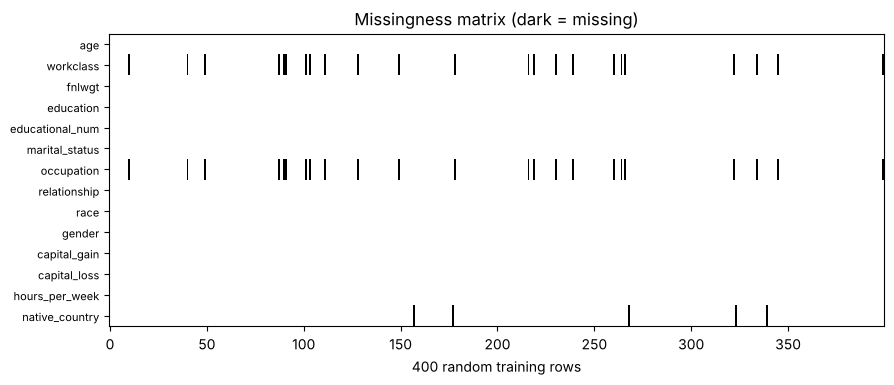

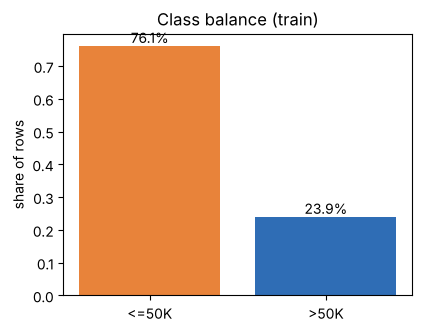

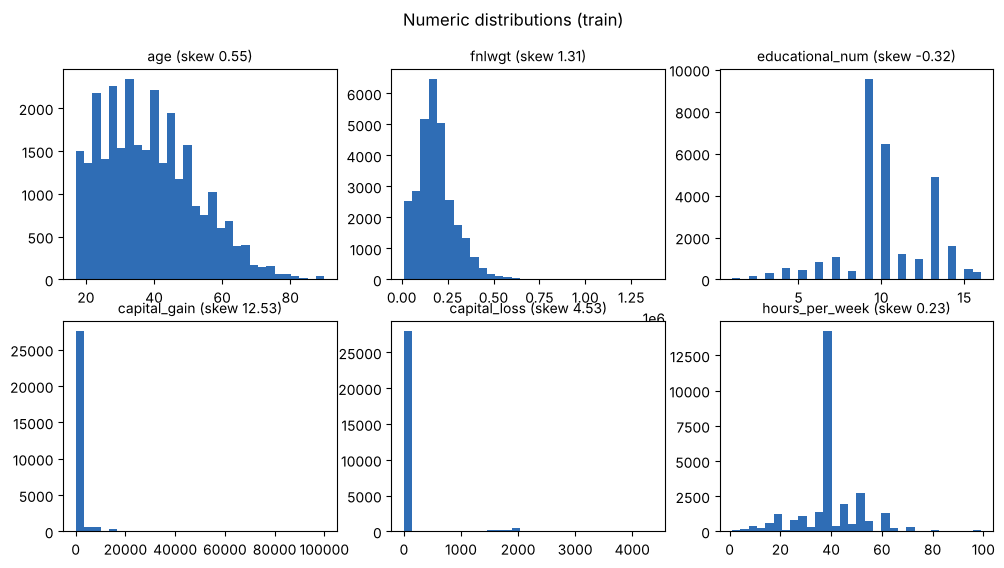

In [5]:
eda = eda_summary(X_train, y_train)


## 3. Baseline pipeline
Logistic Regression (L2) with one-hot encoding + scaling; median / most-frequent imputation fitted on train only. Also defines the feature block (`add_feature_block` with toggles), the feature specifications, pipelines, metrics and experiment tracking used by every later section.

In [6]:
EDU_GROUP = {**{k: "HS-or-less" for k in ["Preschool", "1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th", "HS-grad"]},
             **{k: "Some-College" for k in ["Some-college", "Assoc-voc", "Assoc-acdm"]}, "Bachelors": "Bachelors",
             **{k: "Advanced" for k in ["Masters", "Prof-school", "Doctorate"]}}
AMERICAS = ["United-States", "Canada", "Mexico", "Puerto-Rico", "Cuba", "Jamaica", "Dominican-Republic", "Haiti", "Guatemala",
            "Honduras", "El-Salvador", "Nicaragua", "Columbia", "Ecuador", "Peru", "Trinadad&Tobago"]
EUROPE = ["England", "Germany", "Italy", "Poland", "Portugal", "France", "Greece", "Ireland", "Hungary", "Scotland", "Yugoslavia", "Holand-Netherlands"]
ASIA = ["India", "Japan", "China", "Iran", "Philippines", "Vietnam", "Taiwan", "Hong", "Laos", "Thailand", "Cambodia"]
REGION = {**{k: "Americas" for k in AMERICAS}, **{k: "Europe" for k in EUROPE}, **{k: "Asia" for k in ASIA}}


def _cross(a, b):
    return a.fillna("Unknown").astype(str) + "_x_" + b.fillna("Unknown").astype(str)


def add_feature_block(df, toggles=(), drop_cols=()):
    """Row-wise (stateless, target-free) feature block. `toggles` = feature keys to switch on.
    Features that must be FITTED (occupation_catboost, native_country_freq) are added inside the sklearn pipeline."""
    t = set(toggles); d = df.copy()
    gain_gt0 = (d["capital_gain"].fillna(0) > 0).astype(int)
    hbin = pd.cut(d["hours_per_week"], bins=[-1, 30, 40, 50, 1000], labels=["<=30", "31-40", "41-50", "51+"]).astype(object)
    if "capital_gain_gt0" in t: d["capital_gain_gt0"] = gain_gt0
    if "capital_loss_gt0" in t: d["capital_loss_gt0"] = (d["capital_loss"].fillna(0) > 0).astype(int)
    if "overtime" in t: d["overtime"] = (d["hours_per_week"] > 40).astype(int)
    if "capital_gain_log" in t: d["capital_gain_log"] = np.log1p(d["capital_gain"].fillna(0))
    if "capital_loss_log" in t: d["capital_loss_log"] = np.log1p(d["capital_loss"].fillna(0))
    if "fnlwgt_log" in t: d["fnlwgt_log"] = np.log1p(d["fnlwgt"])
    if "age_bin" in t: d["age_bin"] = pd.cut(d["age"], bins=[0, 25, 35, 45, 55, 200], labels=["<=25", "26-35", "36-45", "46-55", "56+"]).astype(object)
    if "hours_bin" in t: d["hours_bin"] = hbin
    if "age_x_education_num" in t: d["age_x_education_num"] = d["age"] * d["educational_num"]
    if "education_group" in t: d["education_group"] = d["education"].map(EDU_GROUP)
    if "native_region" in t: d["native_region"] = d["native_country"].map(REGION).fillna("Other")
    if "marital_x_relationship" in t: d["marital_x_relationship"] = _cross(d["marital_status"], d["relationship"])
    if "gain_gt0_x_occupation" in t: d["gain_gt0_x_occupation"] = _cross(gain_gt0.astype(str), d["occupation"])
    if "occupation_x_hours_bin" in t: d["occupation_x_hours_bin"] = _cross(d["occupation"], hbin)
    if "workclass_x_hours_bin" in t: d["workclass_x_hours_bin"] = _cross(d["workclass"], hbin)
    if "gender_x_occupation" in t: d["gender_x_occupation"] = _cross(d["gender"], d["occupation"])
    d = d.drop(columns=[c for c in drop_cols if c in d.columns])
    for c in d.columns:
        if not pd.api.types.is_numeric_dtype(d[c]):
            d[c] = d[c].astype(object)
    return d


def _spec(key, cycle, prompt, group, ftype, definition, deps, leak, why, code, fair=""):
    return dict(key=key, cycle=cycle, prompt=prompt, group=group, type=ftype, definition=definition, dependencies=deps,
                leakage_risk=leak, rationale=why, pseudocode=code, fairness_note=fair)

NOLEAK = "None - row-wise function of raw columns, target never used"
SPECS = [
    # ---- Cycle 1, Template A, invocation A-1
    _spec("capital_gain_gt0", 1, "A-1", "indicators", "binary indicator", "1 if capital_gain > 0 else 0", "capital_gain", NOLEAK,
          "Handles sparsity; flags non-zero gains.", "df['capital_gain_gt0'] = (df['capital_gain'] > 0).astype(int)"),
    _spec("capital_loss_gt0", 1, "A-1", "indicators", "binary indicator", "1 if capital_loss > 0 else 0", "capital_loss", NOLEAK,
          "Same sparsity argument for losses; loss filers differ from non-filers.", "df['capital_loss_gt0'] = (df['capital_loss'] > 0).astype(int)"),
    _spec("capital_gain_log", 1, "A-1", "log_transforms", "numeric transform", "log1p(capital_gain)", "capital_gain", NOLEAK,
          "Heavily skewed; log1p compresses the 99999 tail for a linear model.", "df['capital_gain_log'] = np.log1p(df['capital_gain'])"),
    _spec("capital_loss_log", 1, "A-1", "log_transforms", "numeric transform", "log1p(capital_loss)", "capital_loss", NOLEAK,
          "Heavily skewed; log1p compresses the tail.", "df['capital_loss_log'] = np.log1p(df['capital_loss'])"),
    _spec("fnlwgt_log", 1, "A-1", "log_transforms", "numeric transform", "log1p(fnlwgt)", "fnlwgt", NOLEAK,
          "Census weight is right-skewed; log1p symmetrises it.", "df['fnlwgt_log'] = np.log1p(df['fnlwgt'])"),
    _spec("age_bin", 1, "A-1", "bins", "categorical bin", "age bins: <=25, 26-35, 36-45, 46-55, 56+", "age", NOLEAK,
          "Captures nonlinearity for linear models.", "df['age_bin'] = pd.cut(df['age'], [0,25,35,45,55,200], labels=['<=25','26-35','36-45','46-55','56+'])"),
    _spec("hours_bin", 1, "A-1", "bins", "categorical bin", "hours-per-week bins: <=30, 31-40, 41-50, 51+", "hours_per_week", NOLEAK,
          "Overtime signal; stronger separation.", "df['hours_bin'] = pd.cut(df['hours_per_week'], [-1,30,40,50,1000], labels=['<=30','31-40','41-50','51+'])"),
    # ---- Cycle 1, Template A, invocation A-2
    _spec("overtime", 1, "A-2", "indicators", "binary indicator", "1 if hours_per_week > 40 else 0", "hours_per_week", NOLEAK,
          "Explicit overtime flag (simple, stable).", "df['overtime'] = (df['hours_per_week'] > 40).astype(int)"),
    _spec("age_x_education_num", 1, "A-2", "age_x_education", "numeric interaction", "age * educational_num", "age, educational_num", NOLEAK,
          "Seniority / skill proxy.", "df['age_x_education_num'] = df['age'] * df['educational_num']"),
    _spec("education_group", 1, "A-2", "groupings", "categorical grouping", "education buckets: HS-or-less, Some-College, Bachelors, Advanced", "education", NOLEAK,
          "Collapses 16 education levels to 4 stable buckets.", "df['education_group'] = df['education'].map(EDU_GROUP)"),
    _spec("native_region", 1, "A-2", "groupings", "categorical grouping", "native-country buckets: Americas, Europe, Asia, Other (missing -> Other)", "native_country", NOLEAK,
          "42 sparse countries -> 4 regions; reduces noise.", "df['native_region'] = df['native_country'].map(REGION).fillna('Other')"),
    _spec("occupation_catboost", 1, "A-2", "encodings", "encoding (target, ordered)", "CatBoost (ordered target statistics) encoding of occupation, fitted inside the pipeline on train rows only",
          "occupation, income (train only)", "Medium by nature (uses target) - mitigated: ordered statistics, fitted inside each CV fold's training rows only",
          "Medium-cardinality column; one number instead of 15 dummies.", "enc = ce.CatBoostEncoder(cols=['occupation']); X_tr['occupation_te'] = enc.fit_transform(X_tr, y_tr)['occupation']; X_va = enc.transform(X_va)"),
    _spec("native_country_freq", 1, "A-2", "encodings", "encoding (frequency)", "normalised frequency of native_country, fitted inside the pipeline on train rows only",
          "native_country (train only)", "Low - target never used; counts fitted on train rows only",
          "High-cardinality column; frequency separates the dominant country from rare ones.", "enc = ce.CountEncoder(cols=['native_country'], normalize=True); enc.fit(X_tr)"),
    # ---- Cycle 2, Template B, invocation B-1 (3 interactions to reduce false negatives)
    _spec("marital_x_relationship", 2, "B-1", "interactions", "categorical interaction", "marital_status x relationship (42 possible levels)", "marital_status, relationship", NOLEAK,
          "Married-civ-spouse heads of household are the largest group of missed >50K earners.", "df['marital_x_relationship'] = df['marital_status'] + '_x_' + df['relationship']",
          "marital_status is a sensitive attribute - the cross inherits it; audit TPR gap by marital_status."),
    _spec("gain_gt0_x_occupation", 2, "B-1", "interactions", "categorical interaction", "capital_gain_gt0 x occupation", "capital_gain, occupation", NOLEAK,
          "A capital gain means something different in Exec-managerial than in Other-service.", "df['gain_gt0_x_occupation'] = (df['capital_gain']>0).astype(str) + '_x_' + df['occupation'].fillna('Unknown')",
          "occupation correlates with gender; low direct risk, audit gender TPR gap."),
    _spec("occupation_x_hours_bin", 2, "B-1", "interactions", "categorical interaction", "occupation x hours-per-week bin (hours-per-week x occupation)", "occupation, hours_per_week", NOLEAK,
          "Long hours pay off differently by occupation.", "df['occupation_x_hours_bin'] = df['occupation'].fillna('Unknown') + '_x_' + hours_bin",
          "Low risk; audit gender TPR gap."),
    # ---- Cycle 2, Template B, invocation B-2
    _spec("workclass_x_hours_bin", 2, "B-2", "interactions", "categorical interaction", "workclass x hours-per-week bin", "workclass, hours_per_week", NOLEAK,
          "Self-employed long-hours workers differ from salaried ones.", "df['workclass_x_hours_bin'] = df['workclass'].fillna('Unknown') + '_x_' + hours_bin",
          "Low risk."),
    _spec("gender_x_occupation", 2, "B-2", "interactions", "categorical interaction", "gender x occupation (sex x occupation)", "gender, occupation", NOLEAK,
          "Occupational pay structure may differ by gender.", "df['gender_x_occupation'] = df['gender'] + '_x_' + df['occupation'].fillna('Unknown')",
          "Direct sensitive-attribute interaction - HIGHEST fairness risk; audited for the gender TPR gap before it can be kept.", ),
]
SPEC_BY_KEY = {s["key"]: s for s in SPECS}
KEYS_C1 = [s["key"] for s in SPECS if s["cycle"] == 1]
KEYS_C2 = [s["key"] for s in SPECS if s["cycle"] == 2]
FAIRNESS_AUDITED = {"gender_x_occupation", "marital_x_relationship"}
ENCODER_KEYS = {"occupation_catboost", "native_country_freq"}
DERIVED_SENSITIVE = ["marital_x_relationship", "gender_x_occupation"]   # crosses that contain a sensitive column

TEMPLATE_A = "Given schema + EDA [paste], propose 5 transformations with rationale, leakage risk, and pandas pseudocode; optimize for F1 on >50K."
TEMPLATE_B = "Given validation errors [paste], suggest 3 interactions to reduce false negatives; provide code and fairness notes."
TEMPLATE_C = "Given subgroup metrics [paste], propose mitigations with minimal overall F1 loss; include steps."


def build_prompt(template, context):
    return template.replace("[paste]", "\n----- pasted context -----\n" + context + "\n----- end of pasted context -----\n")


def format_response(prompt_id):
    out = []
    for i, s in enumerate([s for s in SPECS if s["prompt"] == prompt_id], 1):
        out.append(f"{i}. {s['key']}  [{s['type']}]\n   Rationale: {s['rationale']}\n   Leakage risk: {s['leakage_risk']}\n   Pandas pseudocode: {s['pseudocode']}" +
                   (f"\n   Fairness note: {s['fairness_note']}" if s["fairness_note"] else ""))
    return "\n".join(out)


In [7]:
def make_model(name):
    if name == "lr":
        return LogisticRegression(penalty="l2", max_iter=2000, random_state=SEED)
    if name == "rf":
        return RandomForestClassifier(n_estimators=100, min_samples_leaf=3, n_jobs=-1, random_state=SEED)
    if name == "gb":
        return HistGradientBoostingClassifier(max_iter=150, random_state=SEED)
    if name == "xgb":
        from xgboost import XGBClassifier
        return XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1, eval_metric="logloss", random_state=SEED, n_jobs=2, verbosity=0)
    if name == "lgbm":
        from lightgbm import LGBMClassifier
        return LGBMClassifier(n_estimators=200, learning_rate=0.1, random_state=SEED, verbose=-1, n_jobs=2)
    raise ValueError(name)

MODEL_LABEL = {"lr": "Logistic Regression (L2)", "rf": "Random Forest", "gb": "Gradient Boosting (HistGB)", "xgb": "XGBoost", "lgbm": "LightGBM"}


def available_models():
    out = ["lr", "rf", "gb"]
    for n, mod in [("xgb", "xgboost"), ("lgbm", "lightgbm")]:
        try:
            __import__(mod); out.append(n)
        except Exception:
            pass
    return out


def build_pipeline(toggles=(), model="lr", drop_cols=()):
    t = tuple(sorted(toggles)); dc = tuple(drop_cols)
    sample = add_feature_block(DATA["X_train"].head(300), t, dc)
    num_cols = [c for c in sample.columns if pd.api.types.is_numeric_dtype(sample[c])]
    cat_cols = [c for c in sample.columns if c not in num_cols]
    parts = [("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
             ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)]
    if "occupation_catboost" in t and "occupation" in sample.columns:
        parts.append(("occ_cb", Pipeline([("enc", ce.CatBoostEncoder(cols=["occupation"], handle_missing="value", handle_unknown="value")), ("scaler", StandardScaler())]), ["occupation"]))
    if "native_country_freq" in t and "native_country" in sample.columns:
        parts.append(("nat_freq", Pipeline([("enc", ce.CountEncoder(cols=["native_country"], normalize=True, handle_missing="value", handle_unknown="value")), ("scaler", StandardScaler())]), ["native_country"]))
    fe = FunctionTransformer(add_feature_block, kw_args={"toggles": t, "drop_cols": dc}, validate=False)
    return Pipeline([("fe", fe), ("prep", ColumnTransformer(parts, sparse_threshold=0)), ("clf", make_model(model))])


def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return float(thr[int(np.nanargmax(f1[:-1]))])


def compute_metrics(y, p, thr=0.5):
    y = np.asarray(y); pred = (np.asarray(p) >= thr).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p), "F1": f1, "Precision": prec, "Recall": rec,
            "Brier": brier_score_loss(y, p), "threshold": thr, "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}


def report_metrics(y_true, y_pred, y_prob):
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    auc = roc_auc_score(y_true, y_prob)
    print(f"AUC: {auc:.3f} | F1: {f1:.3f} | Precision: {prec:.3f} | Recall: {rec:.3f}")
    return {"AUC": auc, "F1": f1, "Precision": prec, "Recall": rec}


def features_summary(toggles):
    if not toggles:
        return "baseline (raw columns only)"
    order = [s["key"] for s in SPECS if s["key"] in toggles]
    return f"{len(order)} features: " + ", ".join(order)


def evaluate_config(config_id, toggles=(), model="lr", drop_cols=(), comments="", log=True):
    """5-fold stratified CV on TRAIN, then fit on train -> validation (threshold tuned on validation) -> holdout (logged only)."""
    key = (tuple(sorted(toggles)), model, tuple(sorted(drop_cols)))
    if key in CACHE:
        hit = CACHE[key]
        if log and config_id not in CONFIG_ROWS and hit["config_id"] in CONFIG_ROWS:   # same configuration under a new ID: log an alias row, no recompute
            row = dict(LOG[CONFIG_ROWS[hit["config_id"]]])
            row.update({"config_id": config_id, "runtime_sec": 0.0, "comments": (comments + " | " if comments else "") + f"identical configuration to {hit['config_id']} (result reused, not recomputed)"})
            CONFIG_ROWS[config_id] = len(LOG); LOG.append(row)
        return hit
    t0 = time.time(); X, y = DATA["X_train"], DATA["y_train"]
    skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
    aucs, f1s, aps = [], [], []
    for tr, va in skf.split(X, y):
        pipe = build_pipeline(toggles, model, drop_cols).fit(X.iloc[tr], y.iloc[tr])
        p = pipe.predict_proba(X.iloc[va])[:, 1]
        m = compute_metrics(y.iloc[va], p, 0.5)
        aucs.append(m["AUC"]); f1s.append(m["F1"]); aps.append(m["PR_AUC"])
    pipe = build_pipeline(toggles, model, drop_cols).fit(X, y)
    p_val = pipe.predict_proba(DATA["X_val"])[:, 1]; p_test = pipe.predict_proba(DATA["X_test"])[:, 1]
    thr = best_f1_threshold(DATA["y_val"], p_val)
    res = {"config_id": config_id, "toggles": tuple(sorted(toggles)), "model": model, "drop_cols": tuple(drop_cols), "pipe": pipe,
           "cv_auc": np.array(aucs), "cv_f1": np.array(f1s), "cv_ap": np.array(aps), "threshold": thr,
           "p_val": p_val, "p_test": p_test, "val": compute_metrics(DATA["y_val"], p_val, thr), "val_05": compute_metrics(DATA["y_val"], p_val, 0.5),
           "test": compute_metrics(DATA["y_test"], p_test, thr), "test_05": compute_metrics(DATA["y_test"], p_test, 0.5), "runtime": time.time() - t0}
    CACHE[key] = res
    if log:
        CONFIG_ROWS[config_id] = len(LOG)
        LOG.append({"config_id": config_id, "features_enabled": features_summary(toggles) + (f"; dropped columns: {', '.join(drop_cols)}" if drop_cols else ""),
                    "model": MODEL_LABEL[model], "cv_auc_mean": round(res["cv_auc"].mean(), 4), "cv_auc_std": round(res["cv_auc"].std(), 4),
                    "cv_f1_mean": round(res["cv_f1"].mean(), 4), "cv_f1_std": round(res["cv_f1"].std(), 4),
                    "val_auc": round(res["val"]["AUC"], 4), "val_f1": round(res["val"]["F1"], 4), "val_threshold": round(thr, 3),
                    "holdout_auc": round(res["test"]["AUC"], 4), "holdout_f1": round(res["test"]["F1"], 4),
                    "holdout_precision": round(res["test"]["Precision"], 4), "holdout_recall": round(res["test"]["Recall"], 4),
                    "runtime_sec": round(res["runtime"], 1), "comments": comments})
    return res


def annotate(config_id, text):
    if config_id in CONFIG_ROWS:
        row = LOG[CONFIG_ROWS[config_id]]
        row["comments"] = (row["comments"] + " | " if row["comments"] else "") + text


def log_df():
    return pd.DataFrame(LOG)


In [8]:
base = evaluate_config("C0-BASE-LR", (), "lr", comments="Phase 1 baseline: raw columns, median/most-frequent imputation, OHE + scaling")
baseline_metrics = pd.DataFrame([{"split": "validation (threshold tuned on validation)", **{k: round(v, 4) for k, v in base["val"].items()}},
                                 {"split": "validation (threshold 0.5)", **{k: round(v, 4) for k, v in base["val_05"].items()}},
                                 {"split": "5-fold CV on train (threshold 0.5)", "AUC": round(base["cv_auc"].mean(), 4), "F1": round(base["cv_f1"].mean(), 4), "PR_AUC": round(base["cv_ap"].mean(), 4)}])
save_csv(baseline_metrics, "baseline_metrics.csv")
show(baseline_metrics, "Baseline metrics")
print(classification_report(y_val, (base["p_val"] >= base["threshold"]).astype(int), target_names=["<=50K", ">50K"]))



Baseline metrics


,split,AUC,PR_AUC,F1,Precision,Recall,Brier,threshold,TN,FP,FN,TP
0,validation (threshold tuned on validation),0.9070,0.7688,0.6950,0.6621,0.7313,0.1013,0.3645,6559.0,872.0,628.0,1709.0
1,validation (threshold 0.5),0.9070,0.7688,0.6645,0.7420,0.6016,0.1013,0.5000,6942.0,489.0,931.0,1406.0
2,5-fold CV on train (threshold 0.5),0.9037,0.7579,0.6513,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


              precision    recall  f1-score   support

       <=50K       0.91      0.88      0.90      7431
        >50K       0.66      0.73      0.69      2337

    accuracy                           0.85      9768
   macro avg       0.79      0.81      0.80      9768
weighted avg       0.85      0.85      0.85      9768



## 4. FeatureBot cycles (prompts + implementation)
Loop: **Context** (schema, missingness, baseline errors) -> **AI propose** (ideas + rationale + pandas pseudocode, leakage flags) -> **Implement** (toggles + config IDs) -> **Evaluate** (stratified 5-fold CV, deltas, keep winners) -> feature registry.

* **Cycle 1** - Template A (issued twice, A-1 and A-2) gives 10 proposals (13 features).
* **Cycle 2** - Template B (issued twice, B-1 and B-2) targets false negatives with 5 interactions.
* Keep rule (train-only CV): mean gain >= +0.0005 AUC or >= +0.003 F1 and positive in >= 4 of 5 folds; features flagged for fairness must not widen the gender TPR gap by more than 0.01.

In [9]:
def paired_delta(res, ref):
    da, df1 = res["cv_auc"] - ref["cv_auc"], res["cv_f1"] - ref["cv_f1"]
    dz = lambda d: float(d.mean() / d.std(ddof=1)) if d.std(ddof=1) > 0 else 0.0
    return {"d_auc": float(da.mean()), "d_f1": float(df1.mean()), "auc_folds_pos": int((da > 0).sum()), "f1_folds_pos": int((df1 > 0).sum()),
            "auc_effect_size": dz(da), "f1_effect_size": dz(df1)}


def passes_rule(d):
    return (d["d_auc"] >= KEEP_MIN_DAUC and d["auc_folds_pos"] >= KEEP_MIN_FOLDS) or (d["d_f1"] >= KEEP_MIN_DF1 and d["f1_folds_pos"] >= KEEP_MIN_FOLDS)


def gender_tpr_gap(res):
    """|TPR_male - TPR_female| on the validation set at the model's own validation threshold."""
    pred = (res["p_val"] >= res["threshold"]).astype(int); y = DATA["y_val"].values; g = DATA["X_val"]["gender"].values
    tprs = [pred[(g == v) & (y == 1)].mean() for v in np.unique(g)]
    return float(max(tprs) - min(tprs))


def run_cycle(cycle, keys, current):
    """Screen each proposal standalone vs baseline, then stepwise addition vs the current accepted set (CV stability)."""
    base = evaluate_config("C0-BASE-LR", (), "lr")
    screen = {}
    for i, k in enumerate(keys, 1):
        r = evaluate_config(f"C{cycle}-S{i:02d}-{k}", {k}, "lr", comments=f"standalone screen of {k} vs baseline")
        screen[k] = paired_delta(r, base)
    order = sorted(keys, key=lambda k: -screen[k]["d_auc"])
    current = set(current); rows, decisions = [], {}
    for k in keys:
        rows.append({"cycle": cycle, "step": "screen (vs baseline)", "feature": k, "reference": "baseline", **{a: round(b, 5) for a, b in screen[k].items()}, "decision": "", "reason": ""})
    for j, k in enumerate(order, 1):
        ref = evaluate_config(f"C{cycle}-REF{j:02d}", current, "lr", log=False) if current else base
        cand = evaluate_config(f"C{cycle}-W{j:02d}-add-{k}", current | {k}, "lr", comments=f"stepwise: add {k} to {len(current)} accepted feature(s)")
        d = paired_delta(cand, ref); ok = passes_rule(d); reason = ""
        if ok:
            reason = (f"stable gain: dAUC {d['d_auc']:+.4f} ({d['auc_folds_pos']}/5 folds +), dF1 {d['d_f1']:+.4f} ({d['f1_folds_pos']}/5 folds +)")
        else:
            reason = (f"low impact / unstable: dAUC {d['d_auc']:+.4f} ({d['auc_folds_pos']}/5 folds +), dF1 {d['d_f1']:+.4f} ({d['f1_folds_pos']}/5 folds +) below keep rule")
        if ok and k in FAIRNESS_AUDITED:
            gap_before, gap_after = gender_tpr_gap(ref), gender_tpr_gap(cand)
            if gap_after - gap_before > FAIRNESS_TPR_GAP_TOL:
                ok = False; reason = f"fairness risk: gender TPR gap widens {gap_before:.3f} -> {gap_after:.3f} (> {FAIRNESS_TPR_GAP_TOL} tolerance) although dAUC {d['d_auc']:+.4f}"
            else:
                reason += f"; fairness audit passed (gender TPR gap {gap_before:.3f} -> {gap_after:.3f})"
        elif k in FAIRNESS_AUDITED:
            reason += f"; gender TPR gap {gender_tpr_gap(ref):.3f} -> {gender_tpr_gap(cand):.3f}"
        if ok:
            current.add(k)
        decisions[k] = {"kept": ok, "reason": reason, "marginal": d}
        rows.append({"cycle": cycle, "step": f"stepwise #{j} (vs accepted set)", "feature": k, "reference": f"{len(current) - (1 if ok else 0)} accepted", **{a: round(b, 5) for a, b in d.items()},
                     "decision": "KEEP" if ok else "REJECT", "reason": reason})
        annotate(f"C{cycle}-W{j:02d}-add-{k}", ("KEPT" if ok else "REJECTED") + ": " + reason)
    end = evaluate_config(f"C{cycle}-END", current, "lr", comments=f"end of cycle {cycle}: accepted set of {len(current)} feature(s)")
    return {"kept": current, "screen": screen, "decisions": decisions, "table": pd.DataFrame(rows), "end": end}


def build_registry(cycles):
    rows = []
    for c in cycles:
        for k, d in c["screen"].items():
            s = SPEC_BY_KEY[k]; dec = c["decisions"][k]
            rows.append({"name": k, "definition": s["definition"], "type": s["type"], "dependencies": s["dependencies"], "leakage_risk": s["leakage_risk"],
                         "added_in_cycle": s["cycle"], "delta_auc": round(d["d_auc"], 4), "delta_f1": round(d["d_f1"], 4),
                         "notes": ("KEPT. " if dec["kept"] else "REJECTED. ") + dec["reason"] + f". delta_* = standalone CV change vs baseline (mean of {N_FOLDS} folds, F1 at 0.5)."})
    return pd.DataFrame(rows)


def context_text(eda, base, errors, extra=""):
    schema = ", ".join(f"{r.column}({r.dtype}, {r.n_unique} unique)" for r in eda.itertuples() if r.column != "income")
    miss = ", ".join(f"{r.column} {r.pct_missing}%" for r in eda.itertuples() if r.n_missing > 0)
    skew = ", ".join(f"{r.column} {r.skew}" for r in eda.itertuples() if r.dtype == "numeric" and abs(r.skew) > 1)
    bal = DATA["y_train"].mean()
    m = base["val"]
    return (f"SCHEMA: {schema}\nTARGET: income (1 = >50K, 0 = <=50K); >50K share in train = {bal:.1%}\nMISSING ('?' -> NaN): {miss}\nSKEWED NUMERICS (|skew|>1): {skew}\n"
            f"BASELINE (Logistic Regression L2, OHE + scaling) VALIDATION: AUC {m['AUC']:.3f}, F1 {m['F1']:.3f} at threshold {m['threshold']:.2f}, precision {m['Precision']:.3f}, recall {m['Recall']:.3f}\n"
            f"TOP ERRORS:\n{errors}\n{extra}")


def error_summary(res, top=5):
    """Validation errors of a fitted config (false negatives are >50K earners that the model misses)."""
    X, y = DATA["X_val"].copy(), DATA["y_val"].values; pred = (res["p_val"] >= res["threshold"]).astype(int)
    X["fn"] = ((pred == 0) & (y == 1)).astype(int); X["pos"] = (y == 1).astype(int)
    m = res["val"]; lines = [f"confusion counts: TP {m['TP']}, FP {m['FP']}, FN {m['FN']}, TN {m['TN']}; miss rate on >50K (FN / positives) = {m['FN'] / max(m['FN'] + m['TP'], 1):.1%}"]
    X["hours_bin"] = pd.cut(X["hours_per_week"], [-1, 30, 40, 50, 1000], labels=["<=30", "31-40", "41-50", "51+"]).astype(str)
    X["has_gain"] = (X["capital_gain"] > 0).map({True: "gain>0", False: "gain=0"})
    for col in ["occupation", "marital_status", "hours_bin", "has_gain"]:
        g = X.groupby(col)[["fn", "pos"]].sum(); g["miss_rate"] = g["fn"] / g["pos"].clip(lower=1)
        g = g[g["pos"] >= 30].sort_values("fn", ascending=False).head(top)
        lines.append(f"false negatives by {col}: " + "; ".join(f"{i}: {int(r.fn)} FN of {int(r.pos)} positives ({r.miss_rate:.0%})" for i, r in g.iterrows()))
    return "\n".join(lines)


In [10]:
errors_a = error_summary(base)
prompts = {"A-1": build_prompt(TEMPLATE_A, context_text(eda, base, errors_a)),
           "A-2": build_prompt(TEMPLATE_A, context_text(eda, base, errors_a, "HIGH-CARDINALITY / REMAINING IDEAS: occupation (14 levels), native_country (41 levels), education (16 levels), age x education signal not yet captured"))}
for pid in ["A-1", "A-2"]:
    print(f"\n===== PROMPT {pid} =====\n{prompts[pid]}\n\n===== RESPONSE {pid} (recorded) =====\n{format_response(pid)}")
cyc1 = run_cycle(1, KEYS_C1, set())
show(cyc1["table"][cyc1["table"]["step"].str.startswith("stepwise")][["feature", "d_auc", "d_f1", "auc_folds_pos", "f1_folds_pos", "decision", "reason"]], "Cycle 1 - stepwise decisions")
registry_v1 = build_registry([cyc1]); save_csv(registry_v1, "feature_registry_v1.csv")



===== PROMPT A-1 =====
Given schema + EDA 
----- pasted context -----
SCHEMA: age(numeric, 72 unique), workclass(categorical, 8 unique), fnlwgt(numeric, 20164 unique), education(categorical, 16 unique), educational_num(numeric, 16 unique), marital_status(categorical, 7 unique), occupation(categorical, 14 unique), relationship(categorical, 6 unique), race(categorical, 5 unique), gender(categorical, 2 unique), capital_gain(numeric, 120 unique), capital_loss(numeric, 94 unique), hours_per_week(numeric, 93 unique), native_country(categorical, 41 unique)
TARGET: income (1 = >50K, 0 = <=50K); >50K share in train = 23.9%
MISSING ('?' -> NaN): workclass 5.69%, occupation 5.72%, native_country 1.7%
SKEWED NUMERICS (|skew|>1): fnlwgt 1.315, capital_gain 12.533, capital_loss 4.533, income 1.222
BASELINE (Logistic Regression L2, OHE + scaling) VALIDATION: AUC 0.907, F1 0.695 at threshold 0.36, precision 0.662, recall 0.731
TOP ERRORS:
confusion counts: TP 1709, FP 872, FN 628, TN 6559; miss rate 


Cycle 1 - stepwise decisions


,feature,d_auc,d_f1,auc_folds_pos,f1_folds_pos,decision,reason
13,age_bin,0.00389,0.00916,5,5,KEEP,"stable gain: dAUC +0.0039 (5/5 folds +), dF1 +..."
14,capital_gain_gt0,0.00239,0.00605,5,5,KEEP,"stable gain: dAUC +0.0024 (5/5 folds +), dF1 +..."
15,capital_gain_log,0.00008,-0.00014,4,2,REJECT,low impact / unstable: dAUC +0.0001 (4/5 folds...
16,hours_bin,0.00145,0.00354,5,4,KEEP,"stable gain: dAUC +0.0014 (5/5 folds +), dF1 +..."
17,occupation_catboost,0.00056,0.00293,5,4,KEEP,"stable gain: dAUC +0.0006 (5/5 folds +), dF1 +..."
18,capital_loss_log,0.00017,0.00093,3,4,REJECT,low impact / unstable: dAUC +0.0002 (3/5 folds...
19,overtime,-0.00001,-0.00042,2,0,REJECT,low impact / unstable: dAUC -0.0000 (2/5 folds...
20,capital_loss_gt0,0.00016,-0.00053,3,3,REJECT,low impact / unstable: dAUC +0.0002 (3/5 folds...
21,native_region,0.00001,-0.00116,2,0,REJECT,low impact / unstable: dAUC +0.0000 (2/5 folds...
22,fnlwgt_log,-0.00005,0.00006,1,3,REJECT,low impact / unstable: dAUC -0.0001 (1/5 folds...


In [11]:
errors_b = error_summary(cyc1["end"])
prompts["B-1"] = build_prompt(TEMPLATE_B, errors_b); prompts["B-2"] = build_prompt(TEMPLATE_B, errors_b + "\nALREADY PROPOSED IN B-1: marital_status x relationship, capital_gain>0 x occupation, occupation x hours bin")
for pid in ["B-1", "B-2"]:
    print(f"\n===== PROMPT {pid} =====\n{prompts[pid]}\n\n===== RESPONSE {pid} (recorded) =====\n{format_response(pid)}")
cyc2 = run_cycle(2, KEYS_C2, cyc1["kept"])
show(cyc2["table"][cyc2["table"]["step"].str.startswith("stepwise")][["feature", "d_auc", "d_f1", "auc_folds_pos", "f1_folds_pos", "decision", "reason"]], "Cycle 2 - stepwise decisions")
final_set = set(cyc2["kept"])
registry = build_registry([cyc1, cyc2]); save_csv(registry, "feature_registry.csv")
cycle_table = pd.concat([cyc1["table"], cyc2["table"]], ignore_index=True); save_csv(cycle_table, "cycle_results.csv")
show(registry, "Feature registry")



===== PROMPT B-1 =====
Given validation errors 
----- pasted context -----
confusion counts: TP 1791, FP 948, FN 546, TN 6483; miss rate on >50K (FN / positives) = 23.4%
false negatives by occupation: Craft-repair: 93 FN of 257 positives (36%); Prof-specialty: 62 FN of 590 positives (11%); Machine-op-inspct: 61 FN of 91 positives (67%); Sales: 59 FN of 289 positives (20%); Transport-moving: 49 FN of 95 positives (52%)
false negatives by marital_status: Married-civ-spouse: 360 FN of 2020 positives (18%); Never-married: 86 FN of 145 positives (59%); Divorced: 67 FN of 123 positives (54%)
false negatives by hours_bin: 31-40: 306 FN of 1103 positives (28%); 41-50: 103 FN of 686 positives (15%); 51+: 95 FN of 454 positives (21%); <=30: 42 FN of 94 positives (45%)
false negatives by has_gain: gain=0: 521 FN of 1852 positives (28%); gain>0: 25 FN of 485 positives (5%)
----- end of pasted context -----
, suggest 3 interactions to reduce false negatives; provide code and fairness notes.

=====


Cycle 2 - stepwise decisions


,feature,d_auc,d_f1,auc_folds_pos,f1_folds_pos,decision,reason
5,gain_gt0_x_occupation,0.00006,-0.00197,3,1,REJECT,low impact / unstable: dAUC +0.0001 (3/5 folds...
6,workclass_x_hours_bin,-0.00026,-0.00189,2,1,REJECT,low impact / unstable: dAUC -0.0003 (2/5 folds...
7,occupation_x_hours_bin,-0.00022,-0.00124,1,2,REJECT,low impact / unstable: dAUC -0.0002 (1/5 folds...
8,gender_x_occupation,0.00003,-0.00214,3,0,REJECT,low impact / unstable: dAUC +0.0000 (3/5 folds...
9,marital_x_relationship,-0.00006,-0.00094,2,2,REJECT,low impact / unstable: dAUC -0.0001 (2/5 folds...



Feature registry


,name,definition,type,dependencies,leakage_risk,added_in_cycle,delta_auc,delta_f1,notes
0,capital_gain_gt0,1 if capital_gain > 0 else 0,binary indicator,capital_gain,"None - row-wise function of raw columns, targe...",1,0.0026,0.0056,"KEPT. stable gain: dAUC +0.0024 (5/5 folds +),..."
1,capital_loss_gt0,1 if capital_loss > 0 else 0,binary indicator,capital_loss,"None - row-wise function of raw columns, targe...",1,0.0002,0.0017,REJECTED. low impact / unstable: dAUC +0.0002 ...
2,capital_gain_log,log1p(capital_gain),numeric transform,capital_gain,"None - row-wise function of raw columns, targe...",1,0.0024,0.0057,REJECTED. low impact / unstable: dAUC +0.0001 ...
3,capital_loss_log,log1p(capital_loss),numeric transform,capital_loss,"None - row-wise function of raw columns, targe...",1,0.0002,0.0016,REJECTED. low impact / unstable: dAUC +0.0002 ...
4,fnlwgt_log,log1p(fnlwgt),numeric transform,fnlwgt,"None - row-wise function of raw columns, targe...",1,-0.0000,0.0000,REJECTED. low impact / unstable: dAUC -0.0001 ...
5,age_bin,"age bins: <=25, 26-35, 36-45, 46-55, 56+",categorical bin,age,"None - row-wise function of raw columns, targe...",1,0.0039,0.0092,"KEPT. stable gain: dAUC +0.0039 (5/5 folds +),..."
6,hours_bin,"hours-per-week bins: <=30, 31-40, 41-50, 51+",categorical bin,hours_per_week,"None - row-wise function of raw columns, targe...",1,0.0020,0.0063,"KEPT. stable gain: dAUC +0.0014 (5/5 folds +),..."
7,overtime,1 if hours_per_week > 40 else 0,binary indicator,hours_per_week,"None - row-wise function of raw columns, targe...",1,0.0002,0.0024,REJECTED. low impact / unstable: dAUC -0.0000 ...
8,age_x_education_num,age * educational_num,numeric interaction,"age, educational_num","None - row-wise function of raw columns, targe...",1,-0.0001,0.0008,REJECTED. low impact / unstable: dAUC -0.0001 ...
9,education_group,"education buckets: HS-or-less, Some-College, B...",categorical grouping,education,"None - row-wise function of raw columns, targe...",1,-0.0000,0.0002,REJECTED. low impact / unstable: dAUC -0.0000 ...


## 5. Evaluation, ablations, fairness
Ablations (with / without subsets), model comparison (Logistic Regression, Random Forest, Gradient Boosting, XGBoost / LightGBM if available), permutation importance, then subgroup metrics by gender (`sex`), race and marital status with two mitigations: **M1** exclude sensitive features, **M2** per-group thresholds (Template C).

In [12]:
ALL_KEYS = [s["key"] for s in SPECS]


def run_ablations(final_set, cycle1_set):
    """With / without subsets: reference, baseline, + all cycle-2 interactions, all 18 candidates (no pruning), leave-one-feature-out, without bins."""
    final_set = set(final_set)
    full = evaluate_config("FINAL-SET-LR", final_set, "lr")
    rows = [{"ablation": "kept features (reference)", "features": len(final_set), **_abl_row(full, full)}]
    def add(cid, label, keys, note):
        r = evaluate_config(cid, keys, "lr", comments=note)
        rows.append({"ablation": label, "features": len(keys), **_abl_row(r, full)})
    add("C0-BASE-LR", "no engineered features (baseline)", set(), "baseline")
    add("A01-with-all-cycle2", "kept + all five cycle-2 interactions", final_set | set(KEYS_C2), "ablation: add every cycle-2 interaction on top of the kept set")
    add("A02-all-candidates", f"all {len(ALL_KEYS)} candidate features (no pruning)", set(ALL_KEYS), "ablation: no pruning, every proposed feature enabled")
    for i, k in enumerate(sorted(final_set), 3):
        add(f"A{i:02d}-without-{k}", f"without {k}", final_set - {k}, f"ablation: leave-one-feature-out ({k})")
    bins = {k for k in final_set if SPEC_BY_KEY[k]["group"] == "bins"}
    if len(bins) > 1:
        add("A90-without-bins", "without bins (age_bin + hours_bin)", final_set - bins, "ablation: remove the bin group")
    return pd.DataFrame(rows)


def _abl_row(r, ref):
    return {"cv_auc_mean": round(r["cv_auc"].mean(), 4), "cv_auc_std": round(r["cv_auc"].std(), 4), "cv_f1_mean": round(r["cv_f1"].mean(), 4), "cv_f1_std": round(r["cv_f1"].std(), 4),
            "val_auc": round(r["val"]["AUC"], 4), "val_f1": round(r["val"]["F1"], 4), "holdout_auc": round(r["test"]["AUC"], 4), "holdout_f1": round(r["test"]["F1"], 4),
            "delta_cv_auc_vs_final": round(r["cv_auc"].mean() - ref["cv_auc"].mean(), 4), "delta_val_f1_vs_final": round(r["val"]["F1"] - ref["val"]["F1"], 4)}


def compare_models(final_set):
    rows = []
    for m in available_models():
        for label, tg in [("baseline features", ()), ("enhanced features", tuple(final_set))]:
            r = evaluate_config(f"M-{m.upper()}-{'BASE' if not tg else 'ENH'}", tg, m, comments="model comparison")
            rows.append({"model": MODEL_LABEL[m], "feature_set": label, "cv_auc_mean": round(r["cv_auc"].mean(), 4), "cv_f1_mean": round(r["cv_f1"].mean(), 4),
                         "val_auc": round(r["val"]["AUC"], 4), "val_f1": round(r["val"]["F1"], 4), "holdout_auc": round(r["test"]["AUC"], 4), "holdout_f1": round(r["test"]["F1"], 4)})
    return pd.DataFrame(rows)


def importances(lr_res, rec_res):
    """Global importances: LR coefficients (top 15, enhanced LR) and permutation importance of the model of record (validation set, original columns)."""
    pipe = lr_res["pipe"]; names = None
    try:
        names = list(pipe.named_steps["prep"].get_feature_names_out())
    except Exception:
        pass
    coef = pipe.named_steps["clf"].coef_.ravel()
    if names is None or len(names) != len(coef):
        names = [f"f{i}" for i in range(len(coef))]
    coefs = pd.DataFrame({"feature": names, "coefficient": coef, "abs_coefficient": np.abs(coef)}).sort_values("abs_coefficient", ascending=False).head(15).round(4)
    pi = permutation_importance(rec_res["pipe"], DATA["X_val"], DATA["y_val"], scoring="roc_auc", n_repeats=5, random_state=SEED)
    perm = pd.DataFrame({"column": DATA["X_val"].columns, "auc_drop_mean": pi.importances_mean.round(4), "auc_drop_std": pi.importances_std.round(4)}).sort_values("auc_drop_mean", ascending=False)
    return coefs, perm


In [13]:
ablations = run_ablations(final_set, cyc1["kept"]); save_csv(ablations, "ablations.csv"); show(ablations, "Ablations (with / without subsets)")
enh_lr = evaluate_config("FINAL-SET-LR", final_set, "lr")
model_cmp = compare_models(final_set); save_csv(model_cmp, "model_comparison.csv"); show(model_cmp, "Model comparison")
# model of record = enhanced-feature model with the best VALIDATION AUC among the model families (LR, RF, Gradient Boosting, XGBoost / LightGBM if available)
final_model = max(available_models(), key=lambda m: evaluate_config(f"M-{m.upper()}-ENH", final_set, m)["val"]["AUC"])
enh = evaluate_config(f"M-{final_model.upper()}-ENH", final_set, final_model)
print(f"Model of record (best validation AUC with enhanced features): {MODEL_LABEL[final_model]}")
coefs, perm = importances(enh_lr, enh); save_csv(coefs, "lr_top_coefficients.csv"); save_csv(perm, "permutation_importance.csv")
show(coefs, "Top LR coefficients"); show(perm, "Permutation importance (validation, AUC drop)")



Ablations (with / without subsets)


,ablation,features,cv_auc_mean,cv_auc_std,cv_f1_mean,cv_f1_std,val_auc,val_f1,holdout_auc,holdout_f1,delta_cv_auc_vs_final,delta_val_f1_vs_final
0,kept features (reference),4,0.9120,0.0030,0.6730,0.0064,0.9144,0.7057,0.9143,0.6966,0.0000,0.0000
1,no engineered features (baseline),0,0.9037,0.0040,0.6513,0.0118,0.9070,0.6950,0.9066,0.6897,-0.0083,-0.0107
2,kept + all five cycle-2 interactions,9,0.9116,0.0033,0.6707,0.0071,0.9140,0.7046,0.9131,0.6945,-0.0004,-0.0010
3,all 18 candidate features (no pruning),18,0.9119,0.0034,0.6717,0.0066,0.9145,0.7052,0.9136,0.6974,-0.0001,-0.0004
4,without age_bin,3,0.9090,0.0028,0.6625,0.0079,0.9121,0.6980,0.9118,0.6900,-0.0030,-0.0077
5,without capital_gain_gt0,3,0.9097,0.0035,0.6673,0.0066,0.9123,0.7054,0.9118,0.6919,-0.0023,-0.0002
6,without hours_bin,3,0.9107,0.0035,0.6671,0.0093,0.9137,0.7077,0.9133,0.6958,-0.0013,0.0020
7,without occupation_catboost,3,0.9114,0.0030,0.6700,0.0074,0.9136,0.7047,0.9138,0.6986,-0.0006,-0.0010
8,without bins (age_bin + hours_bin),2,0.9074,0.0034,0.6611,0.0083,0.9111,0.6984,0.9106,0.6962,-0.0046,-0.0072



Model comparison


,model,feature_set,cv_auc_mean,cv_f1_mean,val_auc,val_f1,holdout_auc,holdout_f1
0,Logistic Regression (L2),baseline features,0.9037,0.6513,0.9070,0.6950,0.9066,0.6897
1,Logistic Regression (L2),enhanced features,0.9120,0.6730,0.9144,0.7057,0.9143,0.6966
2,Random Forest,baseline features,0.9148,0.6761,0.9167,0.7076,0.9168,0.7099
3,Random Forest,enhanced features,0.9137,0.6724,0.9163,0.7083,0.9159,0.7114
4,Gradient Boosting (HistGB),baseline features,0.9258,0.7038,0.9285,0.7293,0.9270,0.7222
5,Gradient Boosting (HistGB),enhanced features,0.9259,0.7017,0.9290,0.7311,0.9265,0.7215
6,XGBoost,baseline features,0.9276,0.7074,0.9286,0.7285,0.9281,0.7220
7,XGBoost,enhanced features,0.9278,0.7065,0.9296,0.7345,0.9283,0.7288
8,LightGBM,baseline features,0.9251,0.7048,0.9280,0.7315,0.9278,0.7219
9,LightGBM,enhanced features,0.9257,0.7048,0.9293,0.7336,0.9271,0.7224


Model of record (best validation AUC with enhanced features): XGBoost



Top LR coefficients


,feature,coefficient,abs_coefficient
3,num__capital_gain,3.9670,3.9670
32,cat__marital_status_Married-AF-spouse,1.6151,1.6151
33,cat__marital_status_Married-civ-spouse,1.4965,1.4965
68,cat__native_country_Columbia,-1.2755,1.2755
110,cat__age_bin_<=25,-1.2754,1.2754
35,cat__marital_status_Never-married,-1.1368,1.1368
114,cat__hours_bin_<=30,-1.0365,1.0365
85,cat__native_country_Ireland,0.9737,0.9737
99,cat__native_country_South,-0.9733,0.9733
70,cat__native_country_Dominican-Republic,-0.9600,0.9600



Permutation importance (validation, AUC drop)


,column,auc_drop_mean,auc_drop_std
5,marital_status,0.0823,0.0026
10,capital_gain,0.0522,0.0011
0,age,0.0402,0.0013
4,educational_num,0.0277,0.0006
6,occupation,0.0149,0.0006
11,capital_loss,0.0141,0.0007
12,hours_per_week,0.0117,0.0011
7,relationship,0.0029,0.0002
1,workclass,0.0026,0.0003
9,gender,0.0018,0.0003


In [14]:
def subgroup_table(values, y, p, pred, attr, model_name):
    rows = []
    for g in sorted(pd.Series(values).dropna().unique()):
        m = np.asarray(values == g); yt, pp, pr = np.asarray(y)[m], np.asarray(p)[m], np.asarray(pred)[m]
        tp = int(((pr == 1) & (yt == 1)).sum()); fp = int(((pr == 1) & (yt == 0)).sum()); fn = int(((pr == 0) & (yt == 1)).sum()); tn = int(((pr == 0) & (yt == 0)).sum())
        tpr = tp / (tp + fn) if tp + fn else np.nan; fpr = fp / (fp + tn) if fp + tn else np.nan; prec = tp / (tp + fp) if tp + fp else np.nan
        f1 = 2 * prec * tpr / (prec + tpr) if tp and prec == prec and tpr == tpr and (prec + tpr) > 0 else (0.0 if tp + fn else np.nan)
        auc = roc_auc_score(yt, pp) if len(np.unique(yt)) == 2 else np.nan
        rows.append({"model": model_name, "attribute": attr, "group": g, "n": int(m.sum()), "positives": int(yt.sum()), "selection_rate": pr.mean(),
                     "TPR": tpr, "FPR": fpr, "Precision": prec, "Recall": tpr, "F1": f1, "AUC": auc})
    return pd.DataFrame(rows)


def fairness_tables(X, y, p, pred, model_name):
    attrs = [("gender", X["gender"].values), ("race", X["race"].values), ("marital_status", X["marital_status"].values)]
    return pd.concat([subgroup_table(v, y, p, pred, a, model_name) for a, v in attrs], ignore_index=True)


def parity_ratios(sub):
    rows = []
    for (model, attr), g in sub.groupby(["model", "attribute"]):
        g = g[g["n"] >= MIN_GROUP_N]
        for metric in ["selection_rate", "TPR", "FPR"]:
            v = g.dropna(subset=[metric]); 
            if v.empty:
                continue
            lo, hi = v.loc[v[metric].idxmin()], v.loc[v[metric].idxmax()]
            rows.append({"model": model, "attribute": attr, "metric": metric, "lowest_group": lo["group"], "lowest": round(lo[metric], 4), "highest_group": hi["group"],
                         "highest": round(hi[metric], 4), "parity_ratio": round(lo[metric] / hi[metric], 4) if hi[metric] > 0 else np.nan, "gap": round(hi[metric] - lo[metric], 4),
                         "groups_compared": int(len(v)), "note": f"groups with n < {MIN_GROUP_N} excluded"})
    return pd.DataFrame(rows)


def group_thresholds(res, attr="gender"):
    """Mitigation M2: per-group thresholds chosen on VALIDATION so each group's TPR matches the overall validation TPR."""
    X, y, p = DATA["X_val"], DATA["y_val"].values, res["p_val"]
    target = ((p >= res["threshold"]) & (y == 1)).sum() / (y == 1).sum(); thr = {}
    grid = np.unique(np.round(np.quantile(p, np.linspace(0.01, 0.99, 197)), 4))
    for g in X[attr].dropna().unique():
        m = (X[attr] == g).values
        tprs = np.array([((p[m] >= t) & (y[m] == 1)).sum() / max((y[m] == 1).sum(), 1) for t in grid])
        thr[g] = float(grid[int(np.argmin(np.abs(tprs - target)))])
    return thr, float(target)


def predict_with_group_thresholds(X, p, thr, attr="gender"):
    return np.array([int(pp >= thr[g]) for pp, g in zip(p, X[attr].values)])


In [15]:
Xv, yv, Xt, yt = DATA["X_val"], DATA["y_val"].values, DATA["X_test"], DATA["y_test"].values
sub_val = fairness_tables(Xv, yv, enh["p_val"], (enh["p_val"] >= enh["threshold"]).astype(int), "Enhanced (validation)")
prompts["C"] = build_prompt(TEMPLATE_C, sub_val[["attribute", "group", "n", "TPR", "FPR", "Precision", "AUC"]].round(3).to_string(index=False))
print(f"\n===== PROMPT C =====\n{prompts['C']}")
m1_drop = SENSITIVE + DERIVED_SENSITIVE
m1 = evaluate_config("FR-M1-exclude-sensitive", final_set, final_model, drop_cols=m1_drop, comments="mitigation M1: exclude gender, race, marital_status and the crosses that contain them")
thr_g, tpr_target = group_thresholds(enh)
pred_m2_val = predict_with_group_thresholds(Xv, enh["p_val"], thr_g); pred_m2_test = predict_with_group_thresholds(Xt, enh["p_test"], thr_g)
m2_val, m2_test = compute_metrics(yv, enh["p_val"], 0.5), compute_metrics(yt, enh["p_test"], 0.5)
for d_, pr_, y_ in [(m2_val, pred_m2_val, yv), (m2_test, pred_m2_test, yt)]:
    pp, rr, ff, _ = precision_recall_fscore_support(y_, pr_, average="binary", zero_division=0); d_.update({"F1": ff, "Precision": pp, "Recall": rr})
LOG.append({"config_id": "FR-M2-group-thresholds", "features_enabled": features_summary(final_set) + "; per-gender decision thresholds", "model": MODEL_LABEL[final_model],
            "cv_auc_mean": round(enh["cv_auc"].mean(), 4), "cv_auc_std": round(enh["cv_auc"].std(), 4), "cv_f1_mean": round(enh["cv_f1"].mean(), 4), "cv_f1_std": round(enh["cv_f1"].std(), 4),
            "val_auc": round(enh["val"]["AUC"], 4), "val_f1": round(m2_val["F1"], 4), "val_threshold": round(float(np.mean(list(thr_g.values()))), 3),
            "holdout_auc": round(enh["test"]["AUC"], 4), "holdout_f1": round(m2_test["F1"], 4), "holdout_precision": round(m2_test["Precision"], 4), "holdout_recall": round(m2_test["Recall"], 4),
            "runtime_sec": 0.0, "comments": f"mitigation M2: gender-specific thresholds {({k: round(v, 3) for k, v in thr_g.items()})} matching the overall validation TPR {tpr_target:.3f}; same model as the enhanced model of record"})
base_pred_t = (base["p_test"] >= base["threshold"]).astype(int); enh_pred_t = (enh["p_test"] >= enh["threshold"]).astype(int); m1_pred_t = (m1["p_test"] >= m1["threshold"]).astype(int)
subgroup = pd.concat([fairness_tables(Xt, yt, base["p_test"], base_pred_t, "Baseline"), fairness_tables(Xt, yt, enh["p_test"], enh_pred_t, "Enhanced (no mitigation)"),
                      fairness_tables(Xt, yt, m1["p_test"], m1_pred_t, "Enhanced + M1 exclude sensitive features"),
                      fairness_tables(Xt, yt, enh["p_test"], pred_m2_test, "Enhanced + M2 gender thresholds")], ignore_index=True)
parity = parity_ratios(subgroup)
save_csv(subgroup.round(4), "subgroup_metrics.csv"); save_csv(parity, "parity_ratios.csv")
show(subgroup.round(3), "Subgroup metrics (holdout test)"); show(parity, "Parity ratios")



===== PROMPT C =====
Given subgroup metrics 
----- pasted context -----
     attribute                 group    n   TPR   FPR  Precision   AUC
        gender                Female 3238 0.680 0.035      0.696 0.943
        gender                  Male 6530 0.771 0.135      0.715 0.913
          race    Amer-Indian-Eskimo   89 0.385 0.013      0.833 0.883
          race    Asian-Pac-Islander  314 0.722 0.152      0.657 0.887
          race                 Black  954 0.723 0.052      0.686 0.950
          race                 Other   89 0.727 0.064      0.615 0.971
          race                 White 8322 0.764 0.101      0.717 0.928
marital_status              Divorced 1325 0.504 0.013      0.795 0.887
marital_status     Married-AF-spouse    8   NaN 0.125      0.000   NaN
marital_status    Married-civ-spouse 4565 0.800 0.265      0.706 0.860
marital_status Married-spouse-absent  126 0.500 0.036      0.636 0.849
marital_status         Never-married 3189 0.510 0.006      0.813 0.947
mari


Subgroup metrics (holdout test)


,model,attribute,group,n,positives,selection_rate,TPR,FPR,Precision,Recall,F1,AUC
0,Baseline,gender,Female,3206,373,0.102,0.633,0.032,0.720,0.633,0.673,0.941
1,Baseline,gender,Male,6563,1965,0.339,0.738,0.168,0.652,0.738,0.692,0.881
2,Baseline,race,Amer-Indian-Eskimo,97,14,0.093,0.571,0.012,0.889,0.571,0.696,0.948
3,Baseline,race,Asian-Pac-Islander,292,78,0.329,0.795,0.159,0.646,0.795,0.713,0.884
4,Baseline,race,Black,972,120,0.107,0.633,0.033,0.731,0.633,0.679,0.931
5,Baseline,race,Other,84,9,0.095,0.556,0.040,0.625,0.556,0.588,0.920
6,Baseline,race,White,8324,2117,0.280,0.725,0.129,0.658,0.725,0.690,0.902
7,Baseline,marital_status,Divorced,1323,137,0.067,0.460,0.022,0.708,0.460,0.558,0.882
8,Baseline,marital_status,Married-AF-spouse,5,3,0.600,1.000,0.000,1.000,1.000,1.000,1.000
9,Baseline,marital_status,Married-civ-spouse,4464,1976,0.525,0.782,0.320,0.660,0.782,0.716,0.813



Parity ratios


,model,attribute,metric,lowest_group,lowest,highest_group,highest,parity_ratio,gap,groups_compared,note
0,Baseline,gender,selection_rate,Female,0.1023,Male,0.3387,0.3020,0.2364,2,groups with n < 50 excluded
1,Baseline,gender,TPR,Female,0.6327,Male,0.7379,0.8574,0.1052,2,groups with n < 50 excluded
2,Baseline,gender,FPR,Female,0.0325,Male,0.1681,0.1932,0.1356,2,groups with n < 50 excluded
3,Baseline,marital_status,selection_rate,Never-married,0.0250,Married-civ-spouse,0.5249,0.0477,0.4999,6,groups with n < 50 excluded
4,Baseline,marital_status,TPR,Never-married,0.3057,Married-civ-spouse,0.7824,0.3908,0.4767,6,groups with n < 50 excluded
5,Baseline,marital_status,FPR,Widowed,0.0106,Married-civ-spouse,0.3203,0.0332,0.3097,6,groups with n < 50 excluded
6,Baseline,race,selection_rate,Amer-Indian-Eskimo,0.0928,Asian-Pac-Islander,0.3288,0.2822,0.2360,5,groups with n < 50 excluded
7,Baseline,race,TPR,Other,0.5556,Asian-Pac-Islander,0.7949,0.6989,0.2393,5,groups with n < 50 excluded
8,Baseline,race,FPR,Amer-Indian-Eskimo,0.0120,Asian-Pac-Islander,0.1589,0.0758,0.1468,5,groups with n < 50 excluded
9,Enhanced (no mitigation),gender,selection_rate,Female,0.1004,Male,0.3252,0.3089,0.2247,2,groups with n < 50 excluded


## 6. Final model & holdout report
Train the final model on train + validation and evaluate once on the holdout test (threshold chosen on validation). Baseline vs enhanced metrics, confusion matrices, ROC / PR summaries.

In [16]:
def final_fit(toggles, model="lr", drop_cols=(), thr=0.5):
    """Train on train+validation, evaluate ONCE on the holdout test with the validation-chosen threshold."""
    Xf = pd.concat([DATA["X_train"], DATA["X_val"]], ignore_index=True); yf = pd.concat([DATA["y_train"], DATA["y_val"]], ignore_index=True)
    pipe = build_pipeline(toggles, model, drop_cols).fit(Xf, yf)
    p = pipe.predict_proba(DATA["X_test"])[:, 1]
    return pipe, p, compute_metrics(DATA["y_test"], p, thr), compute_metrics(DATA["y_test"], p, 0.5)


def final_figures(y, items):
    """items = [(label, probabilities, metrics-dict)] evaluated on the holdout test."""
    colors = ["#E8833A", "#7A5CC0", "#2F6DB5", "#2E9E5B"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
    for (lab, p, _), c in zip(items, colors):
        fpr, tpr, _t = roc_curve(y, p); axes[0].plot(fpr, tpr, color=c, label=f"{lab} (AUC {roc_auc_score(y, p):.3f})")
        pr, rc, _t = precision_recall_curve(y, p); axes[1].plot(rc, pr, color=c, label=f"{lab} (PR AUC {average_precision_score(y, p):.3f})")
    axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC - holdout test"); axes[0].legend(fontsize=8)
    axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall - holdout test"); axes[1].legend(fontsize=8)
    save_fig(fig, "final_roc_pr.png")
    fig, axes = plt.subplots(1, len(items), figsize=(4.4 * len(items), 3.9))
    for a, (lab, _p, m) in zip(np.atleast_1d(axes), items):
        cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]]); a.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                a.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=13, color="white" if cm[i, j] > cm.max() / 2 else "black")
        a.set_xticks([0, 1]); a.set_xticklabels(["<=50K", ">50K"]); a.set_yticks([0, 1]); a.set_yticklabels(["<=50K", ">50K"])
        a.set_xlabel("Predicted"); a.set_ylabel("Actual"); a.set_title(f"{lab}\n(threshold {m['threshold']:.2f})", fontsize=9)
    save_fig(fig, "final_confusion_matrices.png")



Final holdout metrics


,model,AUC,PR_AUC,F1,Precision,Recall,Brier,threshold,TN,FP,FN,TP
0,"Baseline: Logistic Regression, raw columns (tr...",0.9068,0.7698,0.6888,0.6618,0.7181,0.1014,0.3645,6573,858,659,1679
1,Enhanced LR: FeatureBot features only (train+v...,0.9145,0.7918,0.6994,0.6541,0.7515,0.0968,0.3477,6502,929,581,1757
2,Enhanced model of record: XGBoost - sensitive ...,0.9283,0.8324,0.7234,0.7501,0.6985,0.0873,0.4319,6887,544,705,1633
3,Baseline (threshold 0.5),0.9068,0.7698,0.6588,0.7392,0.5941,0.1014,0.5000,6941,490,949,1389
4,Enhanced LR (threshold 0.5),0.9145,0.7918,0.6774,0.7618,0.6099,0.0968,0.5000,6985,446,912,1426
5,Enhanced model of record (threshold 0.5),0.9283,0.8324,0.7132,0.7975,0.6450,0.0873,0.5000,7048,383,830,1508


              precision    recall  f1-score   support

       <=50K       0.91      0.93      0.92      7431
        >50K       0.75      0.70      0.72      2338

    accuracy                           0.87      9769
   macro avg       0.83      0.81      0.82      9769
weighted avg       0.87      0.87      0.87      9769



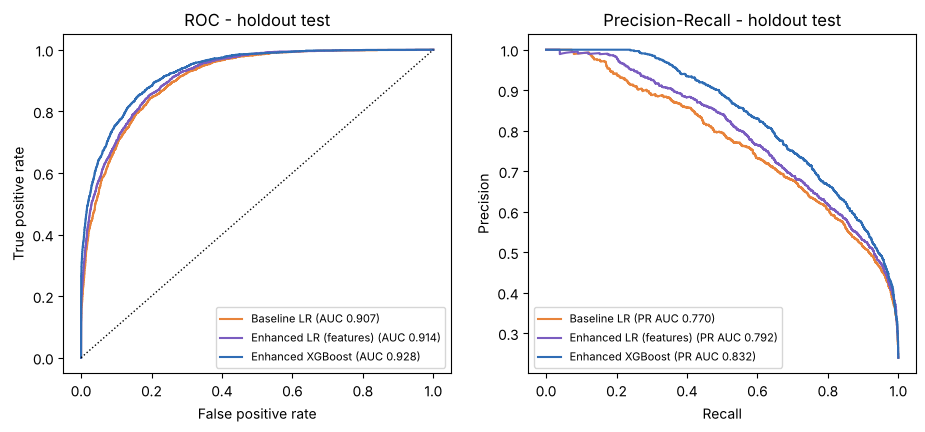

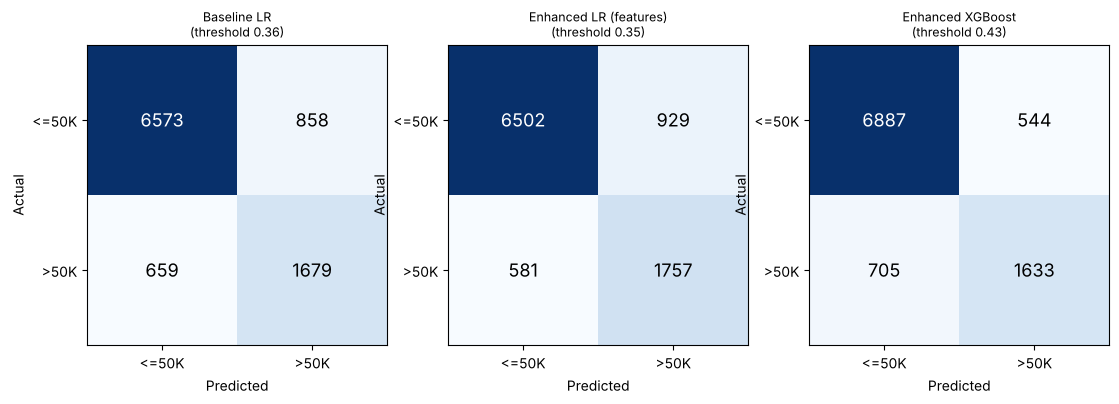


DONE in 3.3 min. Outputs written to ./featurebot_outputs


In [17]:
ADOPT = os.environ.get("FEATUREBOT_ADOPT", "auto")
val_loss_f1, val_loss_auc = enh["val"]["F1"] - m1["val"]["F1"], enh["val"]["AUC"] - m1["val"]["AUC"]
adopt_m1 = (val_loss_f1 <= 0.01 and val_loss_auc <= 0.01) if ADOPT == "auto" else ADOPT == "m1"
final_drop = tuple(m1_drop) if adopt_m1 else ()
chosen = m1 if adopt_m1 else enh
pipe_b, p_b, mb, mb05 = final_fit((), "lr", (), base["threshold"])
pipe_e, p_e, me, me05 = final_fit(final_set, final_model, final_drop, chosen["threshold"])
pipe_l, p_l, ml, ml05 = final_fit(final_set, "lr", (), enh_lr["threshold"])
tag = MODEL_LABEL[final_model] + (" - sensitive features excluded (M1)" if adopt_m1 else "")
final_metrics = pd.DataFrame([{"model": "Baseline: Logistic Regression, raw columns (train+val fit)", **{k: round(v, 4) for k, v in mb.items()}},
                              {"model": "Enhanced LR: FeatureBot features only (train+val fit)", **{k: round(v, 4) for k, v in ml.items()}},
                              {"model": f"Enhanced model of record: {tag} (train+val fit)", **{k: round(v, 4) for k, v in me.items()}},
                              {"model": "Baseline (threshold 0.5)", **{k: round(v, 4) for k, v in mb05.items()}}, {"model": "Enhanced LR (threshold 0.5)", **{k: round(v, 4) for k, v in ml05.items()}},
                              {"model": "Enhanced model of record (threshold 0.5)", **{k: round(v, 4) for k, v in me05.items()}}])
save_csv(final_metrics, "final_metrics.csv"); show(final_metrics, "Final holdout metrics")
print(classification_report(yt, (p_e >= chosen["threshold"]).astype(int), target_names=["<=50K", ">50K"]))
final_figures(yt, [("Baseline LR", p_b, mb), ("Enhanced LR (features)", p_l, ml), (f"Enhanced {MODEL_LABEL[final_model]}", p_e, me)])
LOG.append({"config_id": "F-BASE-LR", "features_enabled": "baseline (raw columns only); trained on train+validation", "model": MODEL_LABEL["lr"], "cv_auc_mean": round(base["cv_auc"].mean(), 4), "cv_auc_std": round(base["cv_auc"].std(), 4),
            "cv_f1_mean": round(base["cv_f1"].mean(), 4), "cv_f1_std": round(base["cv_f1"].std(), 4), "val_auc": round(base["val"]["AUC"], 4), "val_f1": round(base["val"]["F1"], 4), "val_threshold": round(base["threshold"], 3),
            "holdout_auc": round(mb["AUC"], 4), "holdout_f1": round(mb["F1"], 4), "holdout_precision": round(mb["Precision"], 4), "holdout_recall": round(mb["Recall"], 4), "runtime_sec": 0.0,
            "comments": "FINAL baseline: refit on train+validation, holdout evaluated once; CV/validation columns come from the train-only fit of the same configuration"})
LOG.append({"config_id": "F-ENH", "features_enabled": features_summary(final_set) + (f"; dropped columns: {', '.join(final_drop)}" if final_drop else ""), "model": MODEL_LABEL[final_model],
            "cv_auc_mean": round(chosen["cv_auc"].mean(), 4), "cv_auc_std": round(chosen["cv_auc"].std(), 4), "cv_f1_mean": round(chosen["cv_f1"].mean(), 4), "cv_f1_std": round(chosen["cv_f1"].std(), 4),
            "val_auc": round(chosen["val"]["AUC"], 4), "val_f1": round(chosen["val"]["F1"], 4), "val_threshold": round(chosen["threshold"], 3),
            "holdout_auc": round(me["AUC"], 4), "holdout_f1": round(me["F1"], 4), "holdout_precision": round(me["Precision"], 4), "holdout_recall": round(me["Recall"], 4), "runtime_sec": 0.0,
            "comments": "FINAL enhanced: refit on train+validation, holdout evaluated once; " + ("M1 adopted (sensitive features excluded)" if adopt_m1 else "no exclusion adopted") + "; CV/validation columns from the train-only fit of the same configuration"})
experiments = log_df(); save_csv(experiments, "experiments_log.csv")
with open(os.path.join(OUT_DIR, "prompts_and_responses.md"), "w") as f:
    f.write("# FeatureBot prompts and recorded responses\n\nResponses are the AI assistant's proposals as recorded in SPECS (featurebot_adult_income.py).\n")
    for pid in ["A-1", "A-2", "B-1", "B-2"]:
        f.write(f"\n## Prompt {pid}\n\n```\n{prompts[pid]}\n```\n\n### Response {pid}\n\n```\n{format_response(pid)}\n```\n")
    f.write(f"\n## Prompt C (fairness)\n\n```\n{prompts['C']}\n```\n")
R.update(dict(base=base, enh=enh, enh_lr=enh_lr, final_model=final_model, ml=ml, ml05=ml05, m1=m1, final_set=sorted(final_set), cycle1_set=sorted(cyc1["kept"]), registry=registry, final_metrics=final_metrics, adopt_m1=adopt_m1,
              thr_g=thr_g, tpr_target=tpr_target, m2_val=m2_val, m2_test=m2_test, mb=mb, me=me, mb05=mb05, me05=me05, runtime=time.time() - t_start,
              val_loss=(val_loss_f1, val_loss_auc), prompts=prompts, models=available_models()))
print(f"\nDONE in {R['runtime'] / 60:.1f} min. Outputs written to ./{OUT_DIR}")


### Export

In [18]:
import shutil
shutil.make_archive('featurebot_outputs', 'zip', OUT_DIR)
print('Created featurebot_outputs.zip')
try:
    from google.colab import files
    files.download('featurebot_outputs.zip')
except ImportError:
    pass

Created featurebot_outputs.zip
